# Ablation — user-intent comparison

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, 'audit')
import ablation_intent_audit as aia

FINAL = Path('result/final')

ABL = {'baseline': 'IaCGOD', 'no-dense-rag': 'NoDenseRAG', 'no-graphrag': 'NoGraphRAG', 'no-planner': 'NoPlanner',
       'no-remediator': 'NoRemediator', 'no-query-rewrite': 'NoQueryRewrite', 'trivy-all-sev': 'TrivyAllSeverities',
       'opencode-retriever': 'OpenCodeRetriever'}
CONDITIONS = {c: [Path('../results') / f'{lang}_Ablation_{name}' / 'results_final.csv' for lang in ('CFN', 'TF')] for c, name in ABL.items()}
RECOMPUTE = False
RESULTS_DIR = Path('ablation_selection/intent_results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {'baseline': '#2a78d6', 'no-dense-rag': '#1baf7a', 'no-graphrag': '#7a5af5', 'no-planner': '#eb6834',
          'no-remediator': '#eda100', 'no-query-rewrite': '#d6408f', 'trivy-all-sev': '#5f6b7a', 'opencode-retriever': '#8c564b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.axisbelow': True})

## 1. Score (or load) every condition

In [2]:
frames = []
for cond, paths in CONDITIONS.items():
    paths = [Path(p) for p in paths]
    if not paths:
        print(f'{cond:14s} -- no result files yet, skipped')
        continue
    cache = RESULTS_DIR / f'{cond}.csv'
    if cache.exists() and not RECOMPUTE:
        res = pd.read_csv(cache)
        print(f'{cond:14s} -- loaded {len(res)} rows from {cache}')
    else:
        df = pd.concat([pd.read_csv(p, engine='python') for p in paths], ignore_index=True)
        res = aia.audit(df, cond, scope='ablation')
        res.to_csv(cache, index=False)
        print(f'{cond:14s} -- scored {len(res)} rows -> {cache}')
    frames.append(res)

res_all = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
scored = res_all[res_all['intent_status'].isin(['evaluated', 'unevaluable'])].copy()
conds = [c for c in CONDITIONS if c in set(res_all.get('condition', []))]

[baseline] cfn   5: 6/6 core, 7/7 all (parsed)


[baseline] cfn   6: 5/6 core, 7/10 all (parsed)


[baseline] cfn  14: 4/4 core, 10/10 all (parsed)


[baseline] cfn  44: 7/7 core, 16/16 all (parsed)


[baseline] cfn  47: 4/7 core, 6/13 all (parsed)


...

[opencode-retriever] tf 339: 9/9 core, 13/13 all (plan)


[opencode-retriever] tf 343: 5/5 core, 6/6 all (plan)


[opencode-retriever] tf 363: 9/10 core, 16/18 all (plan)


[opencode-retriever] tf 369: 13/14 core, 23/25 all (plan)


opencode-retriever -- scored 100 rows -> ablation_selection/intent_results/opencode-retriever.csv


## 2. Coverage — which rows could be scored

In [3]:
cov = res_all.pivot_table(index=['condition', 'lang'], columns='intent_status', values='row_number',
                          aggfunc='count', fill_value=0)
display(cov)
if (res_all['intent_status'] == 'no_spec').any():
    print('not scored:', res_all.loc[res_all.intent_status == 'no_spec', 'error'].value_counts().to_dict())

intent_status            evaluated  unevaluable
condition          lang                        
baseline           cfn          50            0
                   tf           50            0
no-dense-rag       cfn          50            0
                   tf           48            1
no-graphrag        cfn          50            0
                   tf           50            0
no-planner         cfn          50            0
                   tf           49            1
no-query-rewrite   cfn          50            0
                   tf           50            0
no-remediator      cfn          50            0
                   tf           50            0
opencode-retriever cfn          50            0
                   tf           48            2
trivy-all-sev      cfn          50            0
                   tf           50            0

## 3. Headline summary

In [4]:
summary = aia.summarise(res_all)
display(summary.round(3))

,condition,lang,n_scored,n_unevaluable,intent_strict_rate,mean_core_score,mean_intent_score,mean_resource_score,mean_attribute_score,mean_relationship_score
0,baseline,cfn,50,0,0.700,0.941,0.944,0.976,0.938,0.953
1,baseline,tf,50,0,0.820,0.970,0.965,0.963,0.953,0.929
2,no-dense-rag,cfn,50,0,0.720,0.951,0.955,0.973,0.937,0.934
3,no-dense-rag,tf,49,1,0.837,0.948,0.944,0.943,0.946,0.945
4,no-graphrag,cfn,50,0,0.720,0.956,0.953,0.971,0.951,0.962
5,no-graphrag,tf,50,0,0.880,0.973,0.967,0.984,0.944,0.984
6,no-planner,cfn,50,0,0.900,0.985,0.980,0.993,0.985,0.979
7,no-planner,tf,50,1,0.860,0.966,0.965,0.967,0.965,0.927
8,no-query-rewrite,cfn,50,0,0.700,0.950,0.939,0.968,0.940,0.954
9,no-query-rewrite,tf,50,0,0.760,0.963,0.960,0.975,0.947,0.941


## 4. Strict intent pass rate by difficulty level

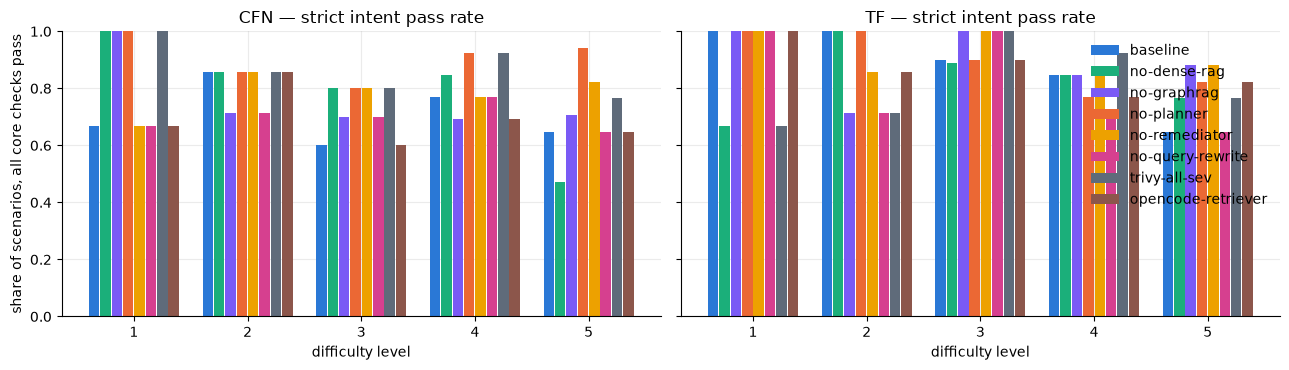

condition        baseline  no-dense-rag  no-graphrag  no-planner  \
lang difficulty                                                    
cfn  1               0.67          1.00         1.00        1.00   
     2               0.86          0.86         0.71        0.86   
     3               0.60          0.80         0.70        0.80   
     4               0.77          0.85         0.69        0.92   
     5               0.65          0.47         0.71        0.94   
tf   1               1.00          0.67         1.00        1.00   
     2               1.00          1.00         0.71        1.00   
     3               0.90          0.89         1.00        0.90   
     4               0.85          0.85         0.85        0.77   
     5               0.65          0.76         0.88        0.82   

condition        no-query-rewrite  no-remediator  opencode-retriever  \
lang difficulty                                                        
cfn  1                       0.67           0.67                0.67   
     2                       0.71           0.86                0.86   
     3                       0.70           0.80                0.60   
     4                       0.77           0.77                0.69   
     5                       0.65           0.82                0.65   
tf   1                       1.00           1.00                1.00   
     2                       0.71           0.86                0.86   
     3                       1.00           1.00                0.90   
     4                       0.69           0.85                0.77   
     5                       0.65           0.88                0.82   

condition        trivy-all-sev  
lang difficulty                 
cfn  1                    1.00  
     2                    0.86  
     3                    0.80  
     4                    0.92  
     5                    0.76  
tf   1                    0.67  
     2                    0.71  
     3                    1.00  
     4                    0.92  
     5                    0.76

In [5]:
langs = [l for l in ('cfn', 'tf') if l in set(scored['lang'])]
fig, axes = plt.subplots(1, len(langs), figsize=(6.5 * len(langs), 3.8), sharey=True, squeeze=False)
by_level = scored.groupby(['lang', 'condition', 'difficulty'])['intent_strict'].mean().rename('rate').reset_index()
width = 0.8 / max(1, len(conds))
for ax, lang in zip(axes[0], langs):
    sub = by_level[by_level['lang'] == lang]
    for i, c in enumerate(conds):
        s = sub[sub['condition'] == c].sort_values('difficulty')
        ax.bar(s['difficulty'] + (i - (len(conds) - 1) / 2) * width, s['rate'], width=width * 0.92,
               color=COLORS.get(c, '#888'), label=c)
    ax.set_title(f'{lang.upper()} — strict intent pass rate')
    ax.set_xlabel('difficulty level'); ax.set_xticks([1, 2, 3, 4, 5]); ax.set_ylim(0, 1)
axes[0][0].set_ylabel('share of scenarios, all core checks pass')
axes[0][-1].legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()
display(by_level.pivot_table(index=['lang', 'difficulty'], columns='condition', values='rate').round(2))

## 5. Which kind of intent is lost — per-category scores

resource_score  attribute_score  relationship_score  \
lang condition                                                                 
cfn  baseline                     0.976            0.938               0.953   
     no-dense-rag                 0.973            0.937               0.934   
     no-graphrag                  0.971            0.951               0.962   
     no-planner                   0.993            0.985               0.979   
     no-query-rewrite             0.968            0.940               0.954   
     no-remediator                0.985            0.948               0.977   
     opencode-retriever           0.958            0.937               0.912   
     trivy-all-sev                0.979            0.965               0.974   
tf   baseline                     0.963            0.953               0.929   
     no-dense-rag                 0.943            0.946               0.945   
     no-graphrag                  0.984            0.944               0.984   
     no-planner                   0.967            0.965               0.927   
     no-query-rewrite             0.975            0.947               0.941   
     no-remediator                0.986            0.995               0.958   
     opencode-retriever           0.938            0.926               0.933   
     trivy-all-sev                0.969            0.950               0.923   

                         output_score  
lang condition                         
cfn  baseline                   0.946  
     no-dense-rag               0.982  
     no-graphrag                0.946  
     no-planner                 0.940  
     no-query-rewrite           0.946  
     no-remediator              0.964  
     opencode-retriever         1.000  
     trivy-all-sev              1.000  
tf   baseline                   0.750  
     no-dense-rag               1.000  
     no-graphrag                1.000  
     no-planner                 0.750  
     no-query-rewrite           0.750  
     no-remediator              1.000  
     opencode-retriever         1.000  
     trivy-all-sev              1.000

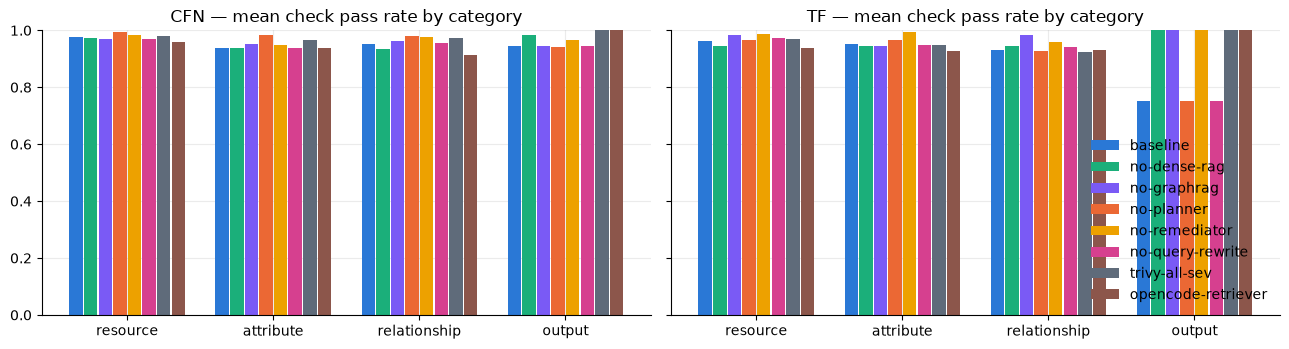

In [6]:
cats = ['resource_score', 'attribute_score', 'relationship_score', 'output_score']
cat_tbl = scored.groupby(['lang', 'condition'])[cats].mean()
display(cat_tbl.round(3))
fig, axes = plt.subplots(1, len(langs), figsize=(6.5 * len(langs), 3.6), sharey=True, squeeze=False)
for ax, lang in zip(axes[0], langs):
    t = cat_tbl.loc[lang]
    for i, c in enumerate(conds):
        if c not in t.index:
            continue
        ax.bar([j + (i - (len(conds) - 1) / 2) * width for j in range(len(cats))], t.loc[c, cats],
               width=width * 0.92, color=COLORS.get(c, '#888'), label=c)
    ax.set_xticks(range(len(cats))); ax.set_xticklabels([x.replace('_score', '') for x in cats])
    ax.set_ylim(0, 1); ax.set_title(f'{lang.upper()} — mean check pass rate by category')
axes[0][-1].legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

## 6. Paired comparison against the baseline

In [7]:
def mcnemar_p(b, c):
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

rows = []
if 'baseline' in conds:
    base = scored[scored['condition'] == 'baseline'].set_index(['lang', 'row_number'])['intent_strict']
    for c in conds:
        if c == 'baseline':
            continue
        other = scored[scored['condition'] == c].set_index(['lang', 'row_number'])['intent_strict']
        for lang in langs:
            j = pd.concat([base, other], axis=1, keys=['b', 'o'], join='inner').xs(lang, level=0, drop_level=False)
            lost = int(((j['b'] == True) & (j['o'] != True)).sum())
            gained = int(((j['b'] != True) & (j['o'] == True)).sum())
            rows.append({'condition': c, 'lang': lang, 'n_paired': len(j), 'baseline_rate': j['b'].mean(),
                         'condition_rate': j['o'].mean(), 'lost': lost, 'gained': gained,
                         'mcnemar_p': mcnemar_p(lost, gained)})
paired = pd.DataFrame(rows)
display(paired.round(3) if len(paired) else 'only the baseline has results so far')

,condition,lang,n_paired,baseline_rate,condition_rate,lost,gained,mcnemar_p
0,no-dense-rag,cfn,50,0.700,0.720,7,8,1.000
1,no-dense-rag,tf,49,0.816,0.837,4,5,1.000
2,no-graphrag,cfn,50,0.700,0.720,6,7,1.000
3,no-graphrag,tf,50,0.820,0.880,4,7,0.549
4,no-planner,cfn,50,0.700,0.900,2,12,0.013
5,no-planner,tf,50,0.820,0.860,3,5,0.727
6,no-remediator,cfn,50,0.700,0.800,5,10,0.302
7,no-remediator,tf,50,0.820,0.900,3,7,0.344
8,no-query-rewrite,cfn,50,0.700,0.700,6,6,1.000
9,no-query-rewrite,tf,50,0.820,0.760,8,5,0.581


## 7. Intent vs deployability

In [8]:
if 'final_validation_passed' in scored:
    ct = (scored.assign(valid=scored['final_validation_passed'].astype(str).str.lower().eq('true'))
          .groupby(['condition', 'lang', 'valid'])['intent_strict'].agg(['count', 'mean']).rename(
              columns={'count': 'n', 'mean': 'intent_strict_rate'}))
    display(ct.round(3))

n  intent_strict_rate
condition          lang valid                        
baseline           cfn  False   1               1.000
                        True   49               0.694
                   tf   True   50               0.820
no-dense-rag       cfn  False   1               1.000
                        True   49               0.714
                   tf   False   2               0.500
                        True   47               0.851
no-graphrag        cfn  True   50               0.720
                   tf   False   2               0.000
                        True   48               0.917
no-planner         cfn  False   2               0.500
                        True   48               0.917
                   tf   False   1               0.000
                        True   49               0.878
no-query-rewrite   cfn  False   1               1.000
                        True   49               0.694
                   tf   False   1               0.000
                        True   49               0.776
no-remediator      cfn  False   2               1.000
                        True   48               0.792
                   tf   False   1               1.000
                        True   49               0.898
opencode-retriever cfn  False   3               0.000
                        True   47               0.723
                   tf   False   3               0.333
                        True   47               0.872
trivy-all-sev      cfn  False   1               1.000
                        True   49               0.837
                   tf   False   1               0.000
                        True   49               0.857

## 8. Most frequently failed checks (per condition)

In [9]:
fc = (scored.assign(check=scored['failed_checks'].fillna('').str.split(';')).explode('check')
      .query('check != ""'))
top = (fc.groupby(['condition', 'lang', 'row_number', 'check']).size().reset_index(name='n')
       .groupby(['condition', 'lang']).head(15))
display(top)

,condition,lang,row_number,check,n
0,baseline,cfn,6,attachment_policy_domain_tag,1
1,baseline,cfn,6,edge_locations_multi_region,1
2,baseline,cfn,6,segment_production,1
3,baseline,cfn,47,account_association,1
4,baseline,cfn,47,agent_space,1
...,...,...,...,...,...
615,trivy-all-sev,tf,76,ingress_3000_anywhere,1
616,trivy-all-sev,tf,76,ingress_5432_anywhere,1
617,trivy-all-sev,tf,90,ignore_estimated_users,1
618,trivy-all-sev,tf,114,var_false_defaults,1
